# Practical Introduction to Machine Learning with Scikit-learn

Welcome to this practical introduction to machine learning! In this notebook, we will explore three fundamental machine learning tasks: **Regression**, **Classification**, and **Clustering**. For each task, we will use datasets provided by `scikit-learn` and implement two different models to understand their application and evaluation.

We will cover:
1.  **Regression**: Predicting a continuous target variable.
2.  **Classification**: Predicting a categorical target variable.
3.  **Clustering**: Discovering inherent groupings in data without prior labels.

## 1. Regression

Regression is a supervised learning task where the goal is to predict a continuous target variable based on one or more input features. We will use the `diabetes` dataset from `scikit-learn`.

In [1]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor # Using RandomForestRegressor for second model
from sklearn.tree import DecisionTreeRegressor # Keep DecisionTreeRegressor for comparison in text
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Diabetes dataset
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = pd.Series(diabetes.target, name='disease_progression')

print("Features (X):")
display(X.head())
print("\nTarget (y):")
display(y.head())

Features (X):


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641



Target (y):


,disease_progression
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0


### Dataset Description: Diabetes
The `diabetes` dataset consists of 10 physiological features (age, sex, body mass index, average blood pressure, and six blood serum measurements) for 442 diabetes patients, and a quantitative measure of disease progression one year after baseline.

**Features (X)**:
*   `age`: age in years
*   `sex`: sex
*   `bmi`: body mass index
*   `bp`: average blood pressure
*   `s1, s2, s3, s4, s5, s6`: six blood serum measurements (e.g., total cholesterol, LDL, HDL, etc.)

**Target (y)**:
*   `disease_progression`: a quantitative measure of disease progression one year after baseline.

### Exploratory Data Analysis (EDA) for Regression
Let's get a basic understanding of our data distribution and potential relationships.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB

DataFrame Description:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


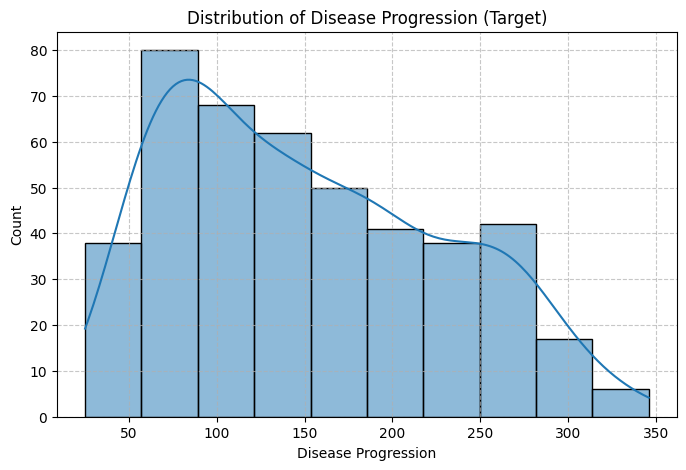

In [2]:
print("DataFrame Info:")
X.info()

print("\nDataFrame Description:")
display(X.describe())

# Visualize distribution of the target variable
plt.figure(figsize=(8, 5))
sns.histplot(y, kde=True)
plt.title('Distribution of Disease Progression (Target)')
plt.xlabel('Disease Progression')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Data Splitting
Before training any model, it's crucial to split our data into training and testing sets. The training set is used to train the model, and the testing set is used to evaluate its performance on unseen data. This helps in assessing the model's generalization capability.

In [3]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 353 samples
Test set size: 89 samples


### Model 1: Linear Regression
Linear Regression is a fundamental supervised learning algorithm used for modeling the relationship between a scalar dependent variable `y` and one or more explanatory variables `X`. It assumes a linear relationship between inputs and output.

**Key Parameters:**
*   `fit_intercept`: Boolean, optional, default: True. Whether to calculate the intercept for this model. If set to False, no intercept will be used in calculations (i.e. data is expected to be already centered).
*   `copy_X`: Boolean, optional, default: True. If True, X will be copied; else, it may be overwritten.
*   `n_jobs`: The number of jobs to use for the computation. This will only provide speedup in case of for example cross-validation. Default is None.

In [4]:
# Initialize and train the Linear Regression model
linear_model = LinearRegression(fit_intercept=True)
linear_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_linear = linear_model.predict(X_test)
print(linear_model.score(X_test, y_test))

# Evaluate the model
mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print(f"Linear Regression Mean Squared Error (MSE): {mse_linear:.2f}")
print(f"Linear Regression R-squared (R2): {r2_linear:.2f}")

0.4526027629719195
Linear Regression Mean Squared Error (MSE): 2900.19
Linear Regression R-squared (R2): 0.45


### Evaluation Metrics for Regression:
*   **Mean Squared Error (MSE):** The average of the squared differences between the predicted and actual values. It penalizes larger errors more heavily. Lower MSE indicates better fit.
*   **R-squared (R2 Score):** Represents the proportion of the variance in the dependent variable that is predictable from the independent variables. R2 ranges from 0 to 1, where 1 indicates a perfect fit. A negative R2 means the model is worse than simply predicting the mean of the target.

### Model 2: Random Forest Regressor
A Random Forest Regressor is an ensemble learning method that fits a number of decision tree regressors on various sub-samples of the dataset and uses averaging to improve the predictive accuracy and control over-fitting. It's known for its robustness and ability to handle non-linear relationships.

**Key Parameters:**
*   `n_estimators`: The number of trees in the forest. More trees generally lead to better performance but also increase computation time.
*   `max_depth`: The maximum depth of the tree. Limiting depth helps prevent overfitting.
*   `random_state`: Controls both the randomness of the bootstrapping of the samples used when building trees and the sampling of the features to consider when looking for the best split. Useful for reproducibility.

In [7]:
# Initialize and train the Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest Regressor MSE: {mse_rf:.2f}")
print(f"Random Forest Regressor R2: {r2_rf:.2f}")

Random Forest Regressor MSE: 2974.20
Random Forest Regressor R2: 0.44


### Regression Model Comparison
Let's compare the performance of both regression models.

Regression Model Performance Comparison:


,Model,MSE,R-squared
0,Linear Regression,2900.193628,0.452603
1,Random Forest Regressor,2974.196170,0.438635


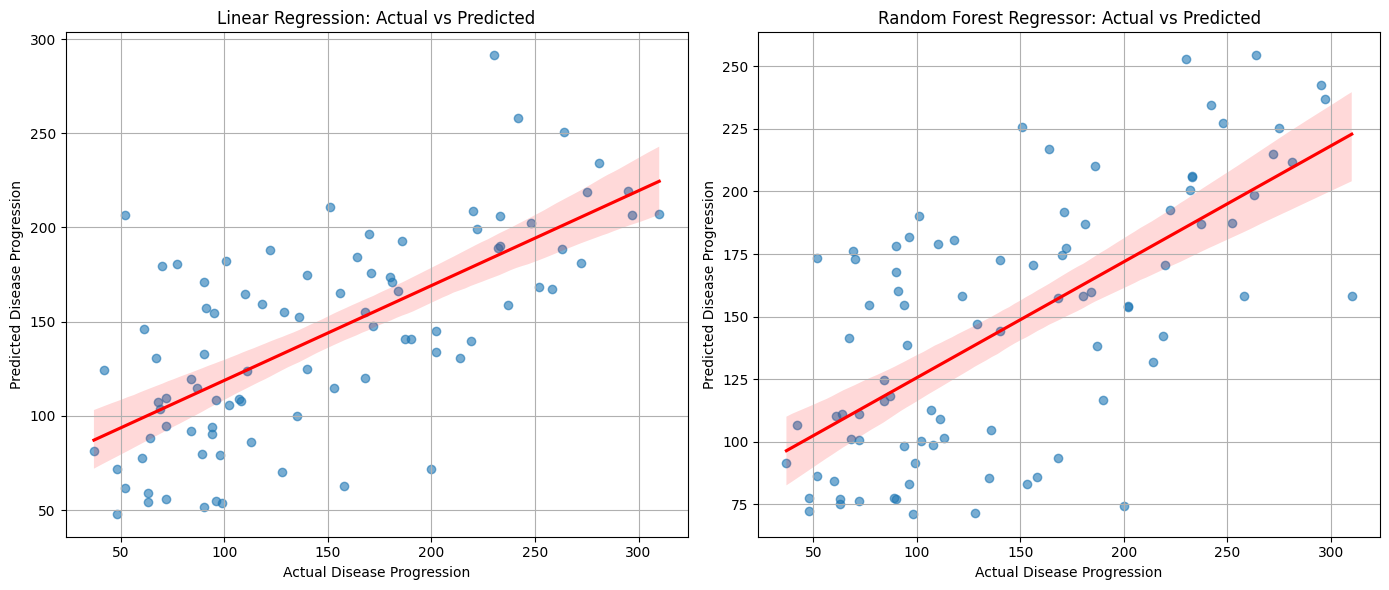

In [ ]:
regression_metrics_data = {
    'Model': ['Linear Regression', 'Random Forest Regressor'],
    'MSE': [mse_linear, mse_rf],
    'R-squared': [r2_linear, r2_rf]
}
regression_metrics_df = pd.DataFrame(regression_metrics_data)

print("Regression Model Performance Comparison:")
display(regression_metrics_df)

# Visualize predictions vs actuals for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Linear Regression
sns.regplot(x=y_test, y=y_pred_linear, scatter_kws={'alpha':0.6}, line_kws={'color':'red'}, ax=axes[0])
axes[0].set_title('Linear Regression: Actual vs Predicted')
axes[0].set_xlabel('Actual Disease Progression')
axes[0].set_ylabel('Predicted Disease Progression')
axes[0].grid(True)

# Random Forest Regressor
sns.regplot(x=y_test, y=y_pred_rf, scatter_kws={'alpha':0.6}, line_kws={'color':'red'}, ax=axes[1])
axes[1].set_title('Random Forest Regressor: Actual vs Predicted')
axes[1].set_xlabel('Actual Disease Progression')
axes[1].set_ylabel('Predicted Disease Progression')
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 2. Classification

Classification is a supervised learning task where the goal is to predict a categorical output variable (a class label). We will use the `iris` dataset from `scikit-learn`.

In [8]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the Iris dataset
iris = load_iris()
X_clf = pd.DataFrame(iris.data, columns=iris.feature_names)
y_clf = pd.Series(iris.target, name='species')

# Map target integers to species names for better readability
species_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
y_clf_names = y_clf.map(species_map)

print("Features (X_clf):")
display(X_clf.head())
print("\nTarget (y_clf_names):")
display(y_clf_names.head())

Features (X_clf):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target (y_clf_names):


,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa


### Dataset Description: Iris
The `iris` dataset is a classic and very easy multi-class classification dataset. It consists of 150 samples of iris flowers, each with 4 features and a corresponding species label.

**Features (X_clf)**:
*   `sepal length (cm)`
*   `sepal width (cm)`
*   `petal length (cm)`
*   `petal width (cm)`

**Target (y_clf)**:
*   `species`: 0 (setosa), 1 (versicolor), 2 (virginica)

### Exploratory Data Analysis (EDA) for Classification
Let's visualize the distribution of classes and how features might separate them.

Class distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


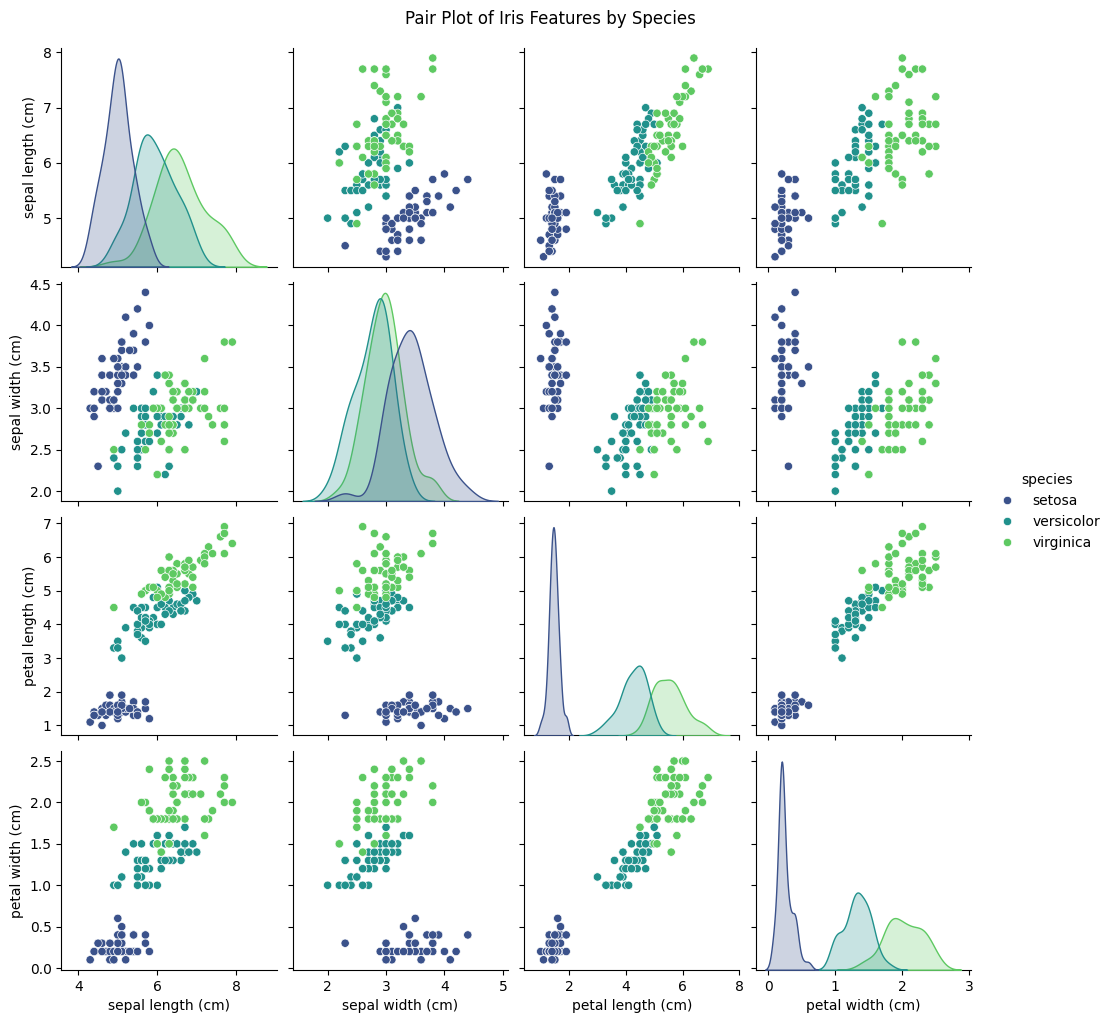

In [9]:
print("Class distribution:")
display(y_clf_names.value_counts())

# Pairplot to visualize relationships between features colored by species
sns.pairplot(pd.concat([X_clf, y_clf_names], axis=1), hue='species', palette='viridis')
plt.suptitle('Pair Plot of Iris Features by Species', y=1.02) # Adjust suptitle position
plt.show()

### Data Splitting
We split the classification data into training and testing sets. For classification, it's important to use `stratify=y_clf` to ensure that the class proportions are maintained in both the training and testing sets, especially if the dataset is imbalanced.

In [10]:
# Split the data into training and testing sets, ensuring stratification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print(f"Training set size: {X_train_clf.shape[0]} samples")
print(f"Test set size: {X_test_clf.shape[0]} samples")
print("\nDistribution of classes in training set:")
print(y_train_clf.value_counts(normalize=True))
print("\nDistribution of classes in test set:")
print(y_test_clf.value_counts(normalize=True))

Training set size: 120 samples
Test set size: 30 samples

Distribution of classes in training set:
species
0    0.333333
2    0.333333
1    0.333333
Name: proportion, dtype: float64

Distribution of classes in test set:
species
0    0.333333
2    0.333333
1    0.333333
Name: proportion, dtype: float64


### Model 1: Logistic Regression
Logistic Regression is a linear model used for binary and multi-class classification. Despite its name, it's a classification algorithm that models the probability of a binary outcome. It uses a logistic function (sigmoid) to output probabilities which are then mapped to class labels.

**Key Parameters:**
*   `solver`: Algorithm to use in the optimization problem. Common choices include 'liblinear', 'lbfgs', 'saga'. Different solvers perform best with different datasets and problem sizes. 'liblinear' is a good choice for smaller datasets.
*   `max_iter`: Maximum number of iterations taken for the solvers to converge. Increase this if the model doesn't converge, especially for 'lbfgs' or 'saga' solvers.
*   `random_state`: Used when `solver` is 'sag', 'saga', or 'lbfgs' to shuffle the data. Ensures reproducibility.

In [11]:
# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(solver='liblinear', max_iter=200, random_state=42)
log_reg_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_log_reg = log_reg_model.predict(X_test_clf)

# Evaluate the model
accuracy_log_reg = accuracy_score(y_test_clf, y_pred_log_reg)
report_log_reg = classification_report(y_test_clf, y_pred_log_reg, target_names=iris.target_names)
conf_matrix_log_reg = confusion_matrix(y_test_clf, y_pred_log_reg)

print(f"Logistic Regression Accuracy: {accuracy_log_reg:.2f}")
print("\nClassification Report:\n", report_log_reg)
print("\nConfusion Matrix:\n", conf_matrix_log_reg)

Logistic Regression Accuracy: 0.97

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


### Evaluation Metrics for Classification:
*   **Accuracy:** The proportion of correctly classified instances out of the total instances. A simple and intuitive metric, but can be misleading for imbalanced datasets.
*   **Precision (for each class):** The ratio of true positive predictions to the total positive predictions for that class (true positives + false positives). Answers: "Of all instances predicted as this class, how many were actually this class?"
*   **Recall (Sensitivity/True Positive Rate for each class):** The ratio of true positive predictions to the total actual positive instances for that class (true positives + false negatives). Answers: "Of all actual instances of this class, how many did we correctly identify?"
*   **F1-Score (for each class):** The harmonic mean of precision and recall. A balanced metric useful when you need to consider both precision and recall. Higher F1-score means better performance.
*   **Support:** The number of actual occurrences of the class in the specified dataset.
*   **Confusion Matrix:** A table that summarizes the performance of a classification algorithm. Each row represents the instances in an actual class while each column represents the instances in a predicted class. This helps visualize types of errors (False Positives, False Negatives for each class).

### Model 2: Support Vector Machine (SVM) Classifier
Support Vector Machines (SVMs) are powerful and versatile supervised machine learning algorithms used for classification. For classification, SVMs work by finding an optimal hyperplane that best separates data points of different classes in a high-dimensional space.

**Key Parameters:**
*   `kernel`: Specifies the kernel type to be used in the algorithm. Common options are 'linear', 'poly' (polynomial), 'rbf' (radial basis function), 'sigmoid'. The choice of kernel significantly affects the model's ability to capture non-linear relationships. 'rbf' (Gaussian Radial Basis Function) is a common and often effective choice for non-linear separation.
*   `C`: Regularization parameter. The strength of the regularization is inversely proportional to C. Smaller values of C encourage a wider margin, but might lead to more misclassifications (underfitting). Larger C values aim for perfect classification on the training data, potentially leading to overfitting.
*   `gamma`: Kernel coefficient for 'rbf', 'poly' and 'sigmoid'. It defines how much influence a single training example has. Small `gamma` means a large influence, while a large `gamma` means a small influence. If `gamma='auto'`, it uses `1 / n_features`.

In [12]:
# Initialize and train the SVM model
svm_model = SVC(kernel='rbf', C=1.0, gamma='auto', random_state=42)
svm_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_svm = svm_model.predict(X_test_clf)

# Evaluate the model
accuracy_svm = accuracy_score(y_test_clf, y_pred_svm)
report_svm = classification_report(y_test_clf, y_pred_svm, target_names=iris.target_names)
conf_matrix_svm = confusion_matrix(y_test_clf, y_pred_svm)

print(f"SVM Accuracy: {accuracy_svm:.2f}")
print("\nClassification Report:\n", report_svm)
print("\nConfusion Matrix:\n", conf_matrix_svm)

SVM Accuracy: 0.97

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


### Classification Model Comparison
Let's summarize and visualize the performance of our classification models.

Classification Model Performance Comparison:


,Model,Accuracy
0,Logistic Regression,0.966667
1,SVM Classifier,0.966667


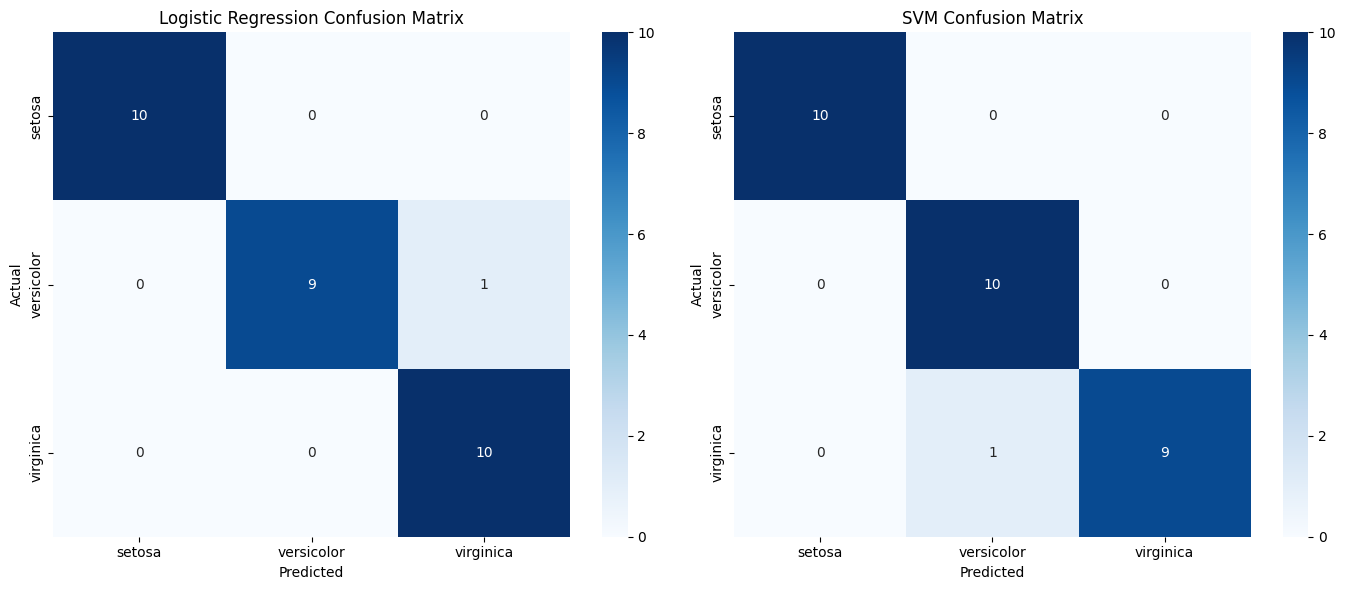

In [13]:
classification_metrics_data = {
    'Model': ['Logistic Regression', 'SVM Classifier'],
    'Accuracy': [accuracy_log_reg, accuracy_svm]
}
classification_metrics_df = pd.DataFrame(classification_metrics_data)

print("Classification Model Performance Comparison:")
display(classification_metrics_df)

# Visualize Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(conf_matrix_log_reg, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names, ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names, ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 3. Clustering

Clustering is an unsupervised learning task, meaning there are no predefined labels or target variables. The goal is to discover inherent groupings or structures within the data. We will use the `wine` dataset from `scikit-learn` for this task.

In [15]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Load the Wine dataset
wine = load_wine()
X_clu = pd.DataFrame(wine.data, columns=wine.feature_names)

print("Features (X_clu):")
display(X_clu.head())

Features (X_clu):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Dataset Description: Wine
The `wine` dataset is a classic dataset for classification and clustering. It contains the results of a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars. The analysis determined the quantities of 13 constituents found in each of the three types of wines.

**Features (X_clu)**:
*   `alcohol`, `malic_acid`, `ash`, `alcalinity_of_ash`, `magnesium`, `total_phenols`, `flavanoids`, `nonflavanoid_phenols`, `proanthocyanins`, `color_intensity`, `hue`, `od280/od315_of_diluted_wines`, `proline`

### Exploratory Data Analysis (EDA) & Preprocessing for Clustering
For clustering, it's often important to scale the features, especially for distance-based algorithms, to prevent features with larger ranges from dominating the distance calculations. We will also perform some basic EDA.

DataFrame Description (before scaling):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



DataFrame Description (after scaling):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02,1.780000e+02
mean,7.943708e-15,3.592632e-16,-4.066660e-15,-7.983626e-17,-7.983626e-17,-3.991813e-17,9.979533e-16,-5.588538e-16,-1.656602e-15,-3.442939e-16,1.636643e-15,2.235415e-15,-1.197544e-16
std,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00
min,-2.434235e+00,-1.432983e+00,-3.679162e+00,-2.671018e+00,-2.088255e+00,-2.107246e+00,-1.695971e+00,-1.868234e+00,-2.069034e+00,-1.634288e+00,-2.094732e+00,-1.895054e+00,-1.493188e+00
25%,-7.882448e-01,-6.587486e-01,-5.721225e-01,-6.891372e-01,-8.244151e-01,-8.854682e-01,-8.275393e-01,-7.401412e-01,-5.972835e-01,-7.951025e-01,-7.675624e-01,-9.522483e-01,-7.846378e-01
50%,6.099988e-02,-4.231120e-01,-2.382132e-02,1.518295e-03,-1.222817e-01,9.595986e-02,1.061497e-01,-1.760948e-01,-6.289785e-02,-1.592246e-01,3.312687e-02,2.377348e-01,-2.337204e-01
75%,8.361286e-01,6.697929e-01,6.981085e-01,6.020883e-01,5.096384e-01,8.089974e-01,8.490851e-01,6.095413e-01,6.291754e-01,4.939560e-01,7.131644e-01,7.885875e-01,7.582494e-01
max,2.259772e+00,3.109192e+00,3.156325e+00,3.154511e+00,4.371372e+00,2.539515e+00,3.062832e+00,2.402403e+00,3.485073e+00,3.435432e+00,3.301694e+00,1.960915e+00,2.971473e+00


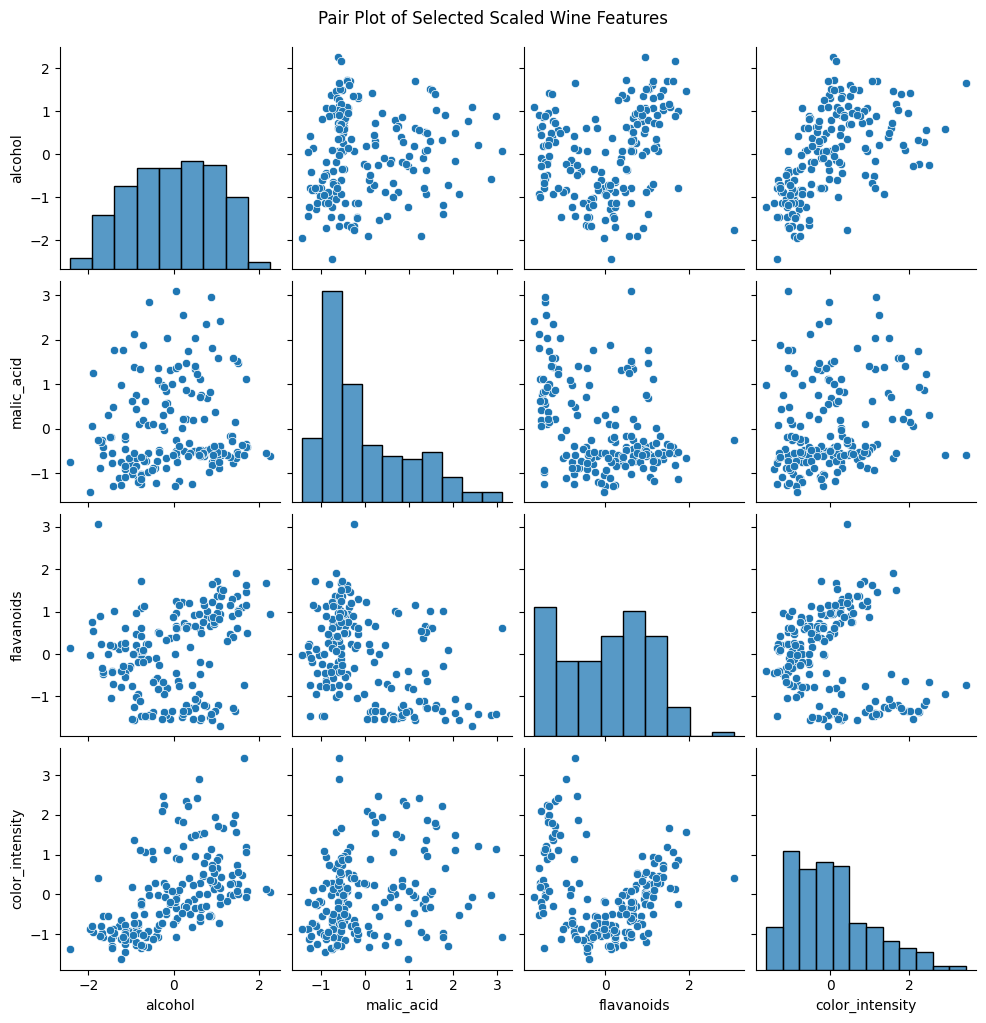

In [16]:
print("DataFrame Description (before scaling):")
display(X_clu.describe())

# Scaling the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clu)
X_scaled_df = pd.DataFrame(X_scaled, columns=wine.feature_names)

print("\nDataFrame Description (after scaling):")
display(X_scaled_df.describe())

# Pairplot of some selected scaled features to visualize clusters (can be slow for many features)
# For demonstration, let's select a few features
sns.pairplot(X_scaled_df[['alcohol', 'malic_acid', 'flavanoids', 'color_intensity']])
plt.suptitle('Pair Plot of Selected Scaled Wine Features', y=1.02)
plt.show()

### Determining the Number of Clusters (Elbow Method for K-Means)
For K-Means, we need to specify the number of clusters (`k`). The Elbow Method is a common heuristic to find an optimal `k` by looking for a 'bend' in the plot of inertia vs. number of clusters.

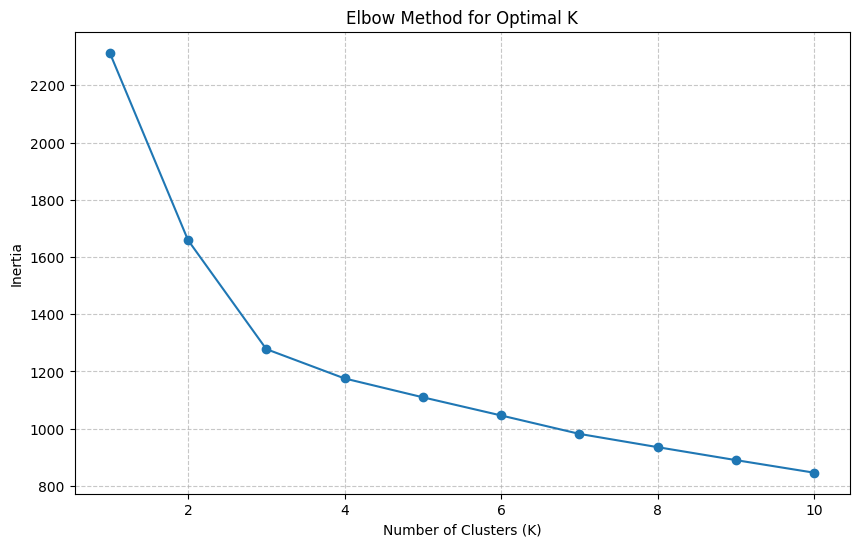

Based on the elbow plot, 3 clusters seems like a reasonable choice for the wine dataset (which has 3 actual classes).


In [17]:
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("Based on the elbow plot, 3 clusters seems like a reasonable choice for the wine dataset (which has 3 actual classes).")

### Model 1: K-Means Clustering
K-Means is a popular centroid-based clustering algorithm. It aims to partition `n` observations into `k` clusters in which each observation belongs to the cluster with the nearest mean (centroid), serving as a prototype of the cluster.

**Key Parameters:**
*   `n_clusters`: The number of clusters to form as well as the number of centroids to generate. This is `k`.
*   `init`: Method for initialization. 'k-means++' is a smart initialization method that speeds up convergence. 'random' is another option.
*   `n_init`: Number of times the k-means algorithm is run with different centroid seeds. The final results is the best output of `n_init` consecutive runs in terms of inertia.
*   `random_state`: Determines random number generation for centroid initialization. Useful for reproducibility.

In [18]:
# Initialize and train the K-Means model
k = 3 # Based on Elbow Method or prior knowledge (wine has 3 cultivars)
kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Evaluate the model
silhouette_kmeans = silhouette_score(X_scaled, kmeans_labels)

print(f"K-Means Silhouette Score: {silhouette_kmeans:.2f}")

# Add cluster labels to the scaled DataFrame for visualization
X_scaled_df['KMeans_Cluster'] = kmeans_labels

K-Means Silhouette Score: 0.28


### Evaluation Metrics for Clustering:
*   **Silhouette Score:** Measures how similar an object is to its own cluster compared to other clusters. It ranges from -1 to +1, where a high value indicates that the object is well matched to its own cluster and poorly matched to neighboring clusters. Scores near 0 indicate overlapping clusters, and negative scores suggest that an object might be assigned to the wrong cluster.
*   **Inertia (within-cluster sum-of-squares):** The sum of squared distances of samples to their closest cluster center. Lower inertia generally indicates better clusters, but it decreases as `k` increases, so it's best used with the Elbow Method.

### Model 2: Agglomerative Clustering
Agglomerative Clustering is a type of hierarchical clustering algorithm. It works in a 'bottom-up' manner, starting with each data point as a single cluster and then iteratively merging the closest pairs of clusters until all clusters have been merged into a single cluster, or a stopping criterion is met.

**Key Parameters:**
*   `n_clusters`: The number of clusters to find. Similar to K-Means, you need to specify `k`.
*   `affinity`: Metric used to compute the linkage. Common options include 'euclidean', 'l1', 'l2', 'manhattan', 'cosine'.
*   `linkage`: Which linkage criterion to use. 'ward' minimizes the variance of the clusters being merged. 'complete' uses the maximum distance between all observations of the two sets. 'average' uses the average of the distances of each observation of the two sets. 'single' uses the minimum of the distances between all observations of the two sets.

In [19]:
# Initialize and train the Agglomerative Clustering model
agg_model = AgglomerativeClustering(n_clusters=k, linkage='ward') # affinity='euclidean' is default for 'ward' linkage
agg_labels = agg_model.fit_predict(X_scaled)

# Evaluate the model
silhouette_agg = silhouette_score(X_scaled, agg_labels)

print(f"Agglomerative Clustering Silhouette Score: {silhouette_agg:.2f}")

# Add cluster labels to the scaled DataFrame for visualization
X_scaled_df['Agg_Cluster'] = agg_labels

Agglomerative Clustering Silhouette Score: 0.28


### Clustering Model Comparison and Visualization
Let's compare the Silhouette Scores and visualize the clusters formed by both algorithms using a dimensionality reduction technique (like PCA) for 2D plotting.

Clustering Model Performance Comparison:


,Model,Silhouette Score
0,K-Means,0.284859
1,Agglomerative Clustering,0.277444


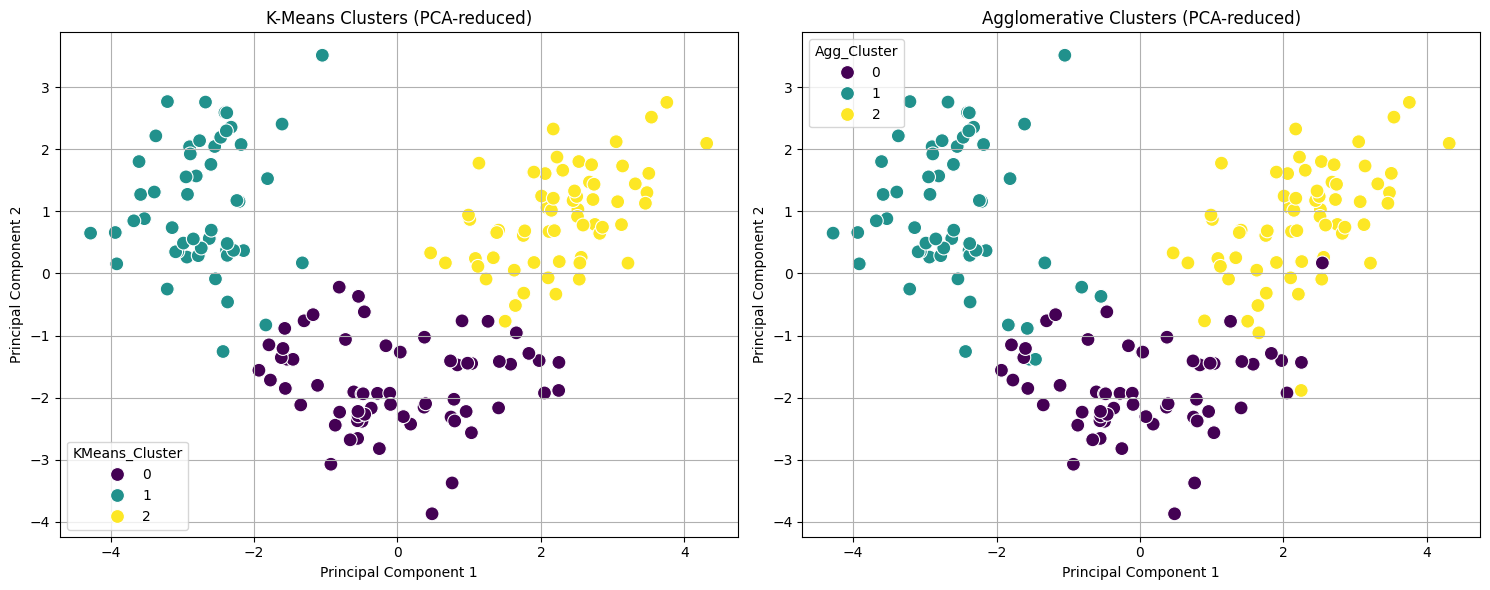

In [20]:
from sklearn.decomposition import PCA

clustering_metrics_data = {
    'Model': ['K-Means', 'Agglomerative Clustering'],
    'Silhouette Score': [silhouette_kmeans, silhouette_agg]
}
clustering_metrics_df = pd.DataFrame(clustering_metrics_data)

print("Clustering Model Performance Comparison:")
display(clustering_metrics_df)

# Reduce dimensions for visualization (e.g., using PCA to 2 components)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
X_pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

X_pca_df['KMeans_Cluster'] = kmeans_labels
X_pca_df['Agg_Cluster'] = agg_labels

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# K-Means Visualization
sns.scatterplot(x='PC1', y='PC2', hue='KMeans_Cluster', data=X_pca_df, palette='viridis', s=100, ax=axes[0])
axes[0].set_title('K-Means Clusters (PCA-reduced)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].grid(True)

# Agglomerative Clustering Visualization
sns.scatterplot(x='PC1', y='PC2', hue='Agg_Cluster', data=X_pca_df, palette='viridis', s=100, ax=axes[1])
axes[1].set_title('Agglomerative Clusters (PCA-reduced)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Conclusion

This notebook provided a practical introduction to three core machine learning tasks:

*   **Regression** with Linear Regression and Random Forest Regressor on the Diabetes dataset.
*   **Classification** with Logistic Regression and Support Vector Machine on the Iris dataset.
*   **Clustering** with K-Means and Agglomerative Clustering on the Wine dataset.

For each task, we followed standard machine learning workflow steps:
1.  **Problem Definition:** Understanding the goal of the task.
2.  **Data Loading & Description:** Getting familiar with the dataset.
3.  **Exploratory Data Analysis (EDA):** Visualizing and understanding data characteristics.
4.  **Data Splitting:** Preparing data for training and testing (for supervised learning).
5.  **Model Training:** Implementing and fitting two different models.
6.  **Parameter Explanation:** Understanding key model configurations.
7.  **Evaluation & Metrics:** Assessing model performance using appropriate metrics and visualizations.

This hands-on approach helps in building a foundational understanding of various ML models and their application in different scenarios.

## 2. Classification

In [ ]:
# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(solver='liblinear', max_iter=200, random_state=42)
log_reg_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_log_reg = log_reg_model.predict(X_test_clf)

# Evaluate the model
accuracy_log_reg = accuracy_score(y_test_clf, y_pred_log_reg)
report_log_reg = classification_report(y_test_clf, y_pred_log_reg, target_names=iris.target_names)
conf_matrix_log_reg = confusion_matrix(y_test_clf, y_pred_log_reg)

print(f"Logistic Regression Accuracy: {accuracy_log_reg:.2f}")
print("\nClassification Report:\n", report_log_reg)
print("\nConfusion Matrix:\n", conf_matrix_log_reg)

### Evaluation Metrics for Classification:
*   **Accuracy:** The proportion of correctly classified instances out of the total instances. A simple and intuitive metric, but can be misleading for imbalanced datasets.
*   **Precision:** The ratio of true positive predictions to the total positive predictions (true positives + false positives). Answers: "Of all instances predicted as positive, how many were actually positive?"
*   **Recall (Sensitivity):** The ratio of true positive predictions to the total actual positive instances (true positives + false negatives). Answers: "Of all actual positive instances, how many did we correctly identify?"
*   **F1-Score:** The harmonic mean of precision and recall. A balanced metric useful when you need to consider both precision and recall.
*   **Confusion Matrix:** A table that summarizes the performance of a classification algorithm. Each row represents the instances in an actual class while each column represents the instances in a predicted class. This helps visualize types of errors (False Positives, False Negatives).

### Model 2: Support Vector Machine (SVM) Classifier
Support Vector Machines (SVMs) are powerful and versatile supervised machine learning algorithms used for classification, regression, and outlier detection. For classification, SVMs work by finding an optimal hyperplane that best separates data points of different classes in a high-dimensional space.

**Key Parameters:**
*   `kernel`: Specifies the kernel type to be used in the algorithm. Common options are 'linear', 'poly' (polynomial), 'rbf' (radial basis function), 'sigmoid'. The choice of kernel significantly affects the model's ability to capture non-linear relationships.
*   `C`: Regularization parameter. The strength of the regularization is inversely proportional to C. Smaller values of C encourage a wider margin, but might lead to more misclassifications. Larger C values aim for perfect classification on the training data, potentially leading to overfitting.

In [ ]:
# Initialize and train the SVM model
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_clf, y_train_clf)

# Make predictions on the test set
y_pred_svm = svm_model.predict(X_test_clf)

# Evaluate the model
accuracy_svm = accuracy_score(y_test_clf, y_pred_svm)
report_svm = classification_report(y_test_clf, y_pred_svm, target_names=iris.target_names)
conf_matrix_svm = confusion_matrix(y_test_clf, y_pred_svm)

print(f"SVM Accuracy: {accuracy_svm:.2f}")
print("\nClassification Report:\n", report_svm)
print("\nConfusion Matrix:\n", conf_matrix_svm)

### Classification Model Comparison
Let's summarize and visualize the performance of our classification models.

In [ ]:
metrics_data_clf = {
    'Model': ['Logistic Regression', 'SVM Classifier'],
    'Accuracy': [accuracy_log_reg, accuracy_svm]
}
metrics_df_clf = pd.DataFrame(metrics_data_clf)

display(metrics_df_clf)

# Visualize Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(conf_matrix_log_reg, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names, ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names, ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()